# The site of metabolism as a prior

`som_oracle.ipynb` used the predicted site as a **gate**: candidates at the predicted atoms
passed, everything else was discarded. That lost 14.2 points. The cause is structural: every wrong prediction deletes an answer permanently, so a predictor that is right 63%
of the time deletes 118 of the 223 answers the rules proposed, and no ranker can return them.

This notebook uses the same predictions as a **prior**. Every candidate stays on the list.
Candidates at a predicted site get a bonus added to the ranker's score:

```
score(candidate) = logP(yes) - logP(no)  +  LAMBDA * [candidate's reacting atoms hit a predicted site]
```

One knob connects the two arms. At `LAMBDA = 0` the arm is arm 6 (46.6%). As `LAMBDA` grows the
site-backed candidates are pushed to the top, which approaches the gate without deleting anything.
If any value in between beats 46.6%, the site information helps once it stops deleting candidates.

`LAMBDA` is chosen on the dev split and applied once to the holdout set.

## 1. Setup: the same candidates, sites and ranker as the gate experiment

In [1]:
import json, os, pathlib, sys, collections, time
import numpy as np, pandas as pd

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "SOM" else pathlib.Path.cwd()
HERE = ROOT / "SOM"
sys.path.insert(0, str(ROOT))
from src import evaluation as ev
from src import decoding as dec
for line in (ROOT / ".env").read_text().splitlines():
    if "=" in line and not line.startswith("#"):
        k, v = line.split("=", 1); os.environ[k.strip()] = v.strip()
import tinker
import tinker.types as tt
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
RDLogger.DisableLog("rdApp.*")

K = 5
rules = pd.read_csv(ROOT / "rules" / "metabolism_rules.csv")
COMPILED = []
for _, r in rules.iterrows():
    rxn = AllChem.ReactionFromSmarts(r["smirks"]); rxn.Initialize()
    COMPILED.append((rxn, bool(r["keep_largest_fragment"])))

def largest_fragment(mol):
    frags = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=False)
    return max(frags, key=lambda f: f.GetNumHeavyAtoms()) if len(frags) > 1 else mol

def enumerate_with_sites(parent, per_rule_cap=200):
    """candidate SMILES -> the parent atom indices its rule reacted at. Same function as the
    gate experiment, so the two arms rank identical lists."""
    mol = Chem.MolFromSmiles(parent)
    if mol is None: return {}
    out = collections.defaultdict(set)
    for rxn, keep in COMPILED:
        try:
            reacting = rxn.GetReactingAtoms()[0]
            matches = mol.GetSubstructMatches(rxn.GetReactantTemplate(0), uniquify=False)
            products = rxn.RunReactants((mol,))
        except Exception:
            continue
        n = 0
        for j, tup in enumerate(products):
            sites = ({matches[j][i] for i in reacting if i < len(matches[j])}
                     if j < len(matches) else set())
            for p in tup:
                try:
                    q = largest_fragment(p) if keep else p
                    Chem.SanitizeMol(q)
                    out[Chem.MolToSmiles(q, canonical=True)] |= sites
                except Exception:
                    pass
                n += 1
                if n > per_rule_cap: break
            if n > per_rule_cap: break
    return dict(out)

test = pd.read_csv(ROOT / "data" / "test_set.csv", dtype=str, keep_default_na=False, na_values=[])
test["parent"] = [ev.canonical(s) for s in test["parent_smiles"]]
test["metabolite"] = [ev.canonical(s) for s in test["metabolite_smiles"]]
test_parents = sorted(set(test["parent"]))

dev_rows = [json.loads(l) for l in (ROOT / "data/processed/dev.jsonl").open()]
dev_by_parent = {}
for r in dev_rows: dev_by_parent.setdefault(r["parent"], set()).add(r["target"])
DEV_N = 60
dev_parents = sorted(np.random.default_rng(0).choice(sorted(dev_by_parent), size=DEV_N, replace=False))

candidates = {p: enumerate_with_sites(p) for p in test_parents + list(dev_parents)}
print(f"holdout: {len(test)} pairs over {len(test_parents)} parents")
print(f"dev probe for choosing LAMBDA: {sum(len(dev_by_parent[p]) for p in dev_parents)} pairs "
      f"over {len(dev_parents)} parents")
print(f"candidates per parent, median {np.median([len(candidates[p]) for p in test_parents]):.0f}")

/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_id" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_seq_id" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(


/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_id" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_name" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_path" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_owner" has conflict with protected namespace "model_".

You may be able to res

holdout: 309 pairs over 155 parents
dev probe for choosing LAMBDA: 98 pairs over 60 parents
candidates per parent, median 32


## 2. Predicted sites

Holdout sites are saved by `som_predictor.ipynb`. Dev parents get predictions from the same
checkpoint, so `LAMBDA` is chosen against predictions of the quality it is applied to.

In [2]:
service = tinker.ServiceClient(api_key=os.environ["TINKER_API_KEY"])
SOM_RUN = json.loads((HERE / "som_predictor_run.json").read_text())
som_client = service.create_sampling_client(model_path=SOM_RUN["best_checkpoint"])
som_tok = som_client.get_tokenizer()
SOM_PROMPT = "<molecule>{}</molecule>\n<site>"

def marked_atoms(smiles, reference_parent):
    """Atom indices carrying map 1, in reference_parent's indexing. breakTies=False so that
    chemically equivalent atoms share a rank (see docs/FINDINGS.md 15)."""
    m = Chem.MolFromSmiles(smiles) if smiles else None
    if m is None: return None
    idx = [a.GetIdx() for a in m.GetAtoms() if a.GetAtomMapNum() == 1]
    if not idx: return None
    for a in m.GetAtoms(): a.SetAtomMapNum(0)
    if Chem.MolToSmiles(m) != reference_parent: return None
    p = Chem.MolFromSmiles(reference_parent)
    rp = list(Chem.CanonicalRankAtoms(p, breakTies=False))
    rm = list(Chem.CanonicalRankAtoms(m, breakTies=False))
    want = {rm[i] for i in idx}
    return {i for i, r in enumerate(rp) if r in want} or None

def predict_sites(parents, n=4, temperature=0.8):
    jobs = {p: som_client.sample(
                prompt=tt.ModelInput.from_ints(som_tok.encode(SOM_PROMPT.format(p))),
                num_samples=n,
                sampling_params=tt.SamplingParams(max_tokens=200, temperature=temperature,
                                                  stop=["</site>", "\n"]))
            for p in parents}
    out = {}
    for p, fut in jobs.items():
        s = set()
        for seq in fut.result().sequences:
            got = marked_atoms(som_tok.decode(seq.tokens).split("</site>")[0].strip(), p)
            if got: s |= got
        out[p] = s
    return out

PRED = {p: set(v) for p, v in json.loads((HERE / "som_predicted_sites.json").read_text())["sites"].items()}
_dev_sites_file = HERE / "som_predicted_sites_dev.json"
if _dev_sites_file.exists():
    dev_sites = {p: set(v) for p, v in json.loads(_dev_sites_file.read_text()).items()}
else:
    dev_sites = predict_sites(list(dev_parents))
    _dev_sites_file.write_text(json.dumps({p: sorted(s) for p, s in dev_sites.items()}, indent=1))
print(f"sites predicted per parent: holdout {np.mean([len(PRED[p]) for p in test_parents]):.2f}, "
      f"dev {np.mean([len(dev_sites[p]) for p in dev_parents]):.2f}")

sites predicted per parent: holdout 3.28, dev 3.37


## 3. Scoring every candidate once

The gate scored only the candidates that survived its filter. A prior scores the whole list: about
33 candidates per parent, two log-probability calls each. Requests are issued across parents to
keep the API busy, and results are cached so the sweep below costs nothing to repeat.

In [3]:
RUN = json.loads((ROOT / "data/processed/reranker_run.json").read_text())
ranker = service.create_sampling_client(model_path=RUN["best_checkpoint"])
tokenizer = ranker.get_tokenizer()
PROMPT = "<parent>{parent}</parent>\n<candidate>{candidate}</candidate>\n"
YES, NO = tokenizer.encode("yes"), tokenizer.encode("no")

def score_all(parent_list, chunk=12, label=""):
    out, t0 = {}, time.time()
    for i in range(0, len(parent_list), chunk):
        batch = parent_list[i:i+chunk]
        jobs = {}
        for p in batch:
            cands = list(candidates.get(p, {}))
            jobs[p] = (cands, [tuple(ranker.compute_logprobs(
                                   prompt=tt.ModelInput.from_ints(
                                       tokenizer.encode(PROMPT.format(parent=p, candidate=c)) + v))
                               for v in (YES, NO)) for c in cands])
        for p, (cands, futs) in jobs.items():
            out[p] = {c: float(y.result()[-1]) - float(n.result()[-1])
                      for c, (y, n) in zip(cands, futs)}
        print(f"  {label} {min(i+chunk, len(parent_list))}/{len(parent_list)}  "
              f"({time.time()-t0:.0f}s)")
    return out

CACHE = HERE / "som_candidate_scores.json"
if CACHE.exists():
    _c = json.loads(CACHE.read_text())
    scores_test, scores_dev = _c["test"], _c["dev"]
    print(f"loaded cached scores for {len(scores_test)} holdout and {len(scores_dev)} dev parents")
else:
    scores_test = score_all(test_parents, label="holdout")
    scores_dev = score_all(list(dev_parents), label="dev")
    CACHE.write_text(json.dumps({"test": scores_test, "dev": scores_dev}))
    print(f"scored and cached {sum(len(v) for v in scores_test.values()):,} holdout candidates "
          f"and {sum(len(v) for v in scores_dev.values()):,} dev candidates")

  holdout 12/155  (8s)


  holdout 24/155  (15s)


  holdout 36/155  (23s)


  holdout 48/155  (30s)


  holdout 60/155  (37s)


...

  dev 12/60  (8s)


  dev 24/60  (15s)


  dev 36/60  (23s)


  dev 48/60  (30s)


  dev 60/60  (38s)
scored and cached 5,243 holdout candidates and 2,091 dev candidates


## 4. Choosing LAMBDA on dev, then applying it once to the holdout set

`LAMBDA` is in the units of the ranker's own score, a difference of log probabilities. The grid
runs from no effect to an effect that dominates any score difference, which is the gate without
the deletion.

In [4]:
def rank_with_prior(parent_list, scores, sites, lam):
    preds = {}
    for p in parent_list:
        cands = list(scores[p])
        if not cands:
            preds[p] = []; continue
        boost = [lam if (candidates[p].get(c, set()) & sites.get(p, set())) else 0.0 for c in cands]
        preds[p] = dec.rank_candidates(cands, [scores[p][c] + b for c, b in zip(cands, boost)],
                                       p, k=K).predictions
    return preds

def recall_at(preds, pairs, k=K):
    hits = 0
    for parent, target in pairs:
        key = ev.match_key(target, "standardized")
        hits += key in {ev.match_key(c, "standardized") for c in preds[parent][:k]}
    return hits / len(pairs)

dev_pairs = [(p, t) for p in dev_parents for t in dev_by_parent[p]]
test_pairs = list(zip(test["parent"], test["metabolite"]))
# Finest resolution between 0.5 and 4, where a 20-parent smoke test put the optimum.
GRID = [0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 8.0, 1e6]

sweep = []
for lam in GRID:
    d = recall_at(rank_with_prior(list(dev_parents), scores_dev, dev_sites, lam), dev_pairs)
    sweep.append({"lambda": lam, "dev_recall5": d})
sw = pd.DataFrame(sweep)
BEST = float(sw.loc[sw["dev_recall5"].idxmax(), "lambda"])
print(sw.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\n  LAMBDA chosen on dev: {BEST:g}")

rows = []
for lam in GRID:
    t = recall_at(rank_with_prior(test_parents, scores_test, PRED, lam), test_pairs)
    t1 = recall_at(rank_with_prior(test_parents, scores_test, PRED, lam), test_pairs, k=1)
    rows.append({"lambda": lam, "holdout_recall1": t1, "holdout_recall5": t,
                 "dev_recall5": float(sw[sw["lambda"] == lam]["dev_recall5"].iloc[0]),
                 "chosen": lam == BEST})
out = pd.DataFrame(rows)
out.to_csv(HERE / "som_prior_results.csv", index=False)
print()
print(out.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

      lambda  dev_recall5
      0.0000       0.5510
      0.2500       0.5510
      0.5000       0.5510
      0.7500       0.5714
      1.0000       0.5714
      1.5000       0.5408
      2.0000       0.5102
      3.0000       0.4898
      4.0000       0.4388
      8.0000       0.3673
1000000.0000       0.3673

  LAMBDA chosen on dev: 0.75



      lambda  holdout_recall1  holdout_recall5  dev_recall5  chosen
      0.0000           0.1812           0.4693       0.5510   False
      0.2500           0.1748           0.4790       0.5510   False
      0.5000           0.1748           0.4757       0.5510   False
      0.7500           0.1780           0.4790       0.5714    True
      1.0000           0.1748           0.4887       0.5714   False
      1.5000           0.1715           0.4951       0.5408   False
      2.0000           0.1748           0.5113       0.5102   False
      3.0000           0.1618           0.4725       0.4898   False
      4.0000           0.1489           0.4498       0.4388   False
      8.0000           0.1456           0.3819       0.3673   False
1000000.0000           0.1456           0.3754       0.3673   False


## 5. What it means

`LAMBDA = 0` should reproduce arm 6: same candidates, same scores, same decoder. It lands one pair
away (46.93% against 46.60%) because scoring is not bit-reproducible (`docs/FINDINGS.md` §16).
A larger gap would mean the two arms are not comparable.

The row chosen on dev is the result. The last row pushes the prior so hard that every site-backed
candidate outranks every other one, which is the gate's ordering without the gate's deletion. The
gap between it and the gate measures what deletion alone costs.

In [5]:
base = float(out[out["lambda"] == 0]["holdout_recall5"].iloc[0])
chosen = out[out["chosen"]].iloc[0]
hard = float(out[out["lambda"] == 1e6]["holdout_recall5"].iloc[0])
gate = float(pd.read_csv(HERE / "som_results.csv")
             .set_index("condition").loc["sites predicted by the model", "recall@5"])
print(f"  LAMBDA = 0, must equal arm 6            : {base:.1%}")
print(f"  LAMBDA = {chosen['lambda']:g}, chosen on dev{'':<14}: {chosen['holdout_recall5']:.1%}"
      f"   ({(chosen['holdout_recall5']-base)*100:+.1f}pp)")
print(f"  prior pushed to dominate the ranking    : {hard:.1%}")
print(f"  the same sites used as a gate           : {gate:.1%}"
      f"   ({(hard-gate)*100:+.1f}pp for not deleting)")

  LAMBDA = 0, must equal arm 6            : 46.9%
  LAMBDA = 0.75, chosen on dev              : 47.9%   (+1.0pp)
  prior pushed to dominate the ranking    : 37.5%
  the same sites used as a gate           : 32.4%   (+5.2pp for not deleting)


## 6. Which chemistry the ranker misses

Each holdout pair is assigned the first rule, in `rules/metabolism_rules.csv` order, that produces
its recorded metabolite, and scored with the `LAMBDA = 0` ranking above. Conjugations and
dealkylations are mostly found. Aliphatic hydroxylation is the largest family and the one most
often ranked too low, and in most of those misses a hydroxylation at a different carbon took a
top-five slot. The ranker knows the reaction but not the atom, which is the information a site of
metabolism carries.

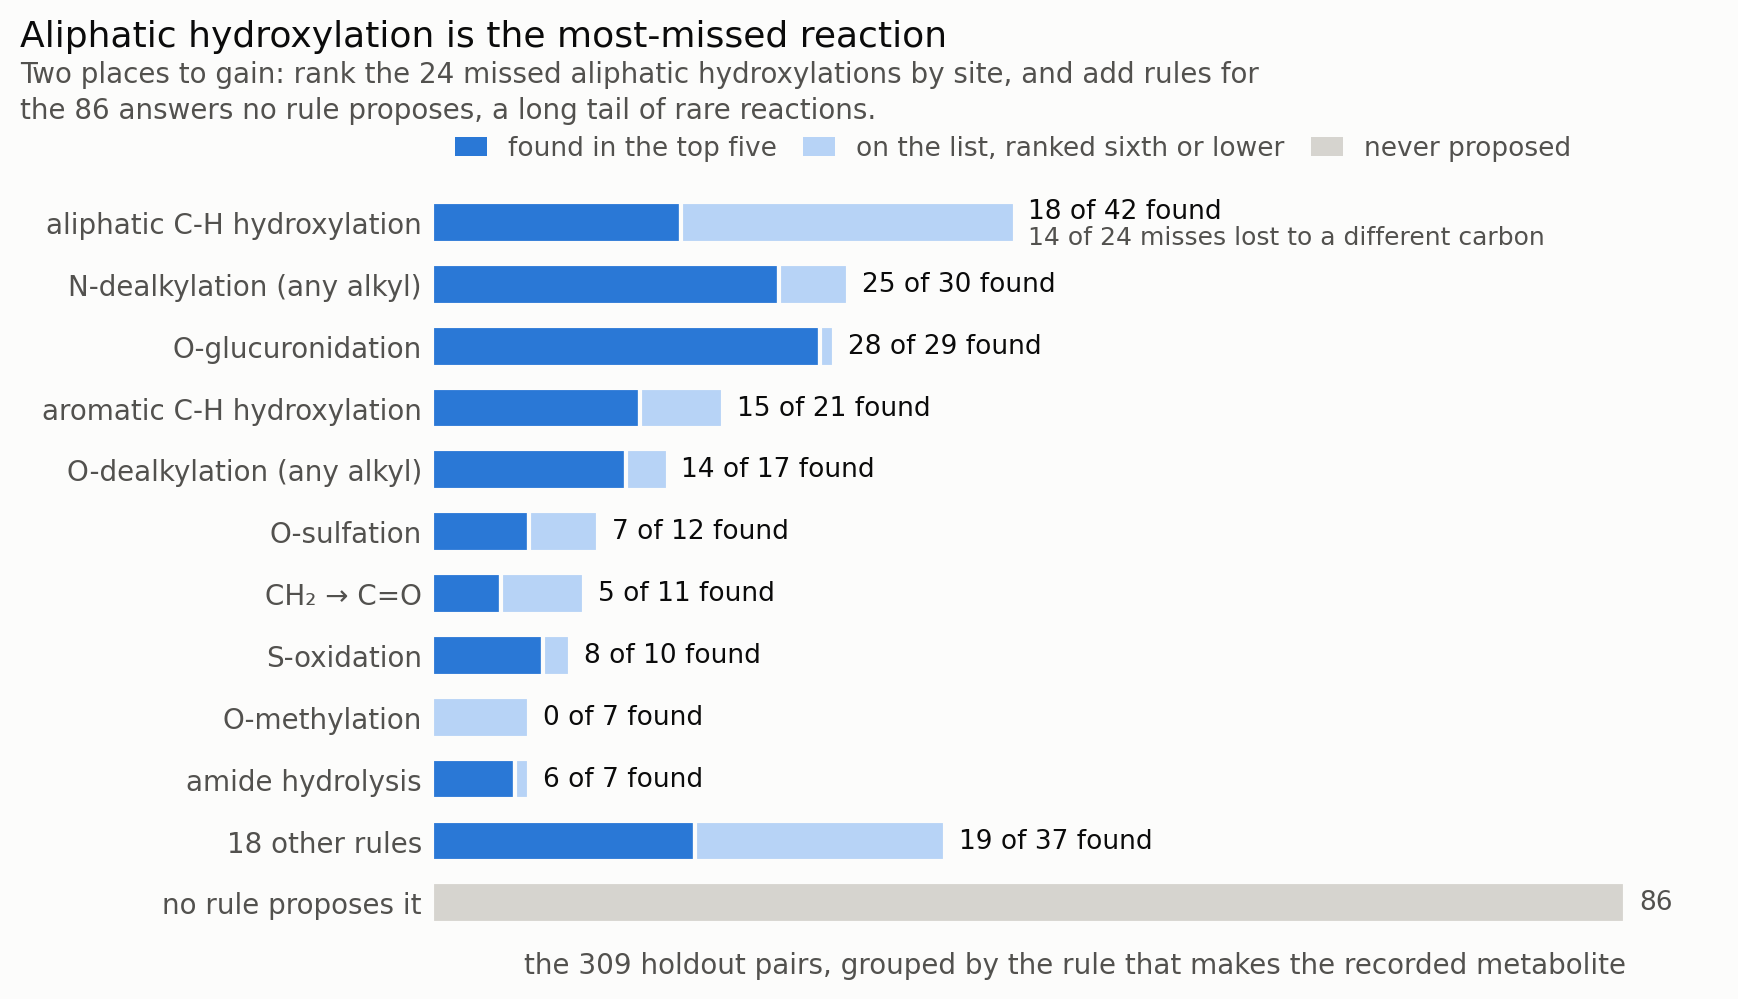

  found 145, on the list but lower 78, never proposed 86

In [ ]:
# Which chemistry the ranker misses. Each holdout pair is assigned the first rule (in CSV order)
# that produces its answer; pairs no rule produces form the last row. Cached scores, no API calls.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

BLUE, PALE, NEVER = "#2a78d6", "#b7d3f6", "#d6d4cf"
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"

NAMED = []
for _, r in rules.iterrows():
    rxn = AllChem.ReactionFromSmarts(r["smirks"]); rxn.Initialize()
    NAMED.append((r["name"], rxn, bool(r["keep_largest_fragment"])))
RULE_ORDER = {name: i for i, (name, _, _) in enumerate(NAMED)}

def rules_by_product(parent, per_rule_cap=200):
    """standardised product key -> the names of the rules that make it."""
    mol = Chem.MolFromSmiles(parent); out = collections.defaultdict(set)
    for name, rxn, keep in NAMED:
        try: products = rxn.RunReactants((mol,))
        except Exception: continue
        n = 0
        for tup in products:
            for p in tup:
                try:
                    q = largest_fragment(p) if keep else p
                    Chem.SanitizeMol(q)
                    key = ev.match_key(Chem.MolToSmiles(q), "standardized")
                    if key: out[key].add(name)
                except Exception:
                    pass
                n += 1
                if n > per_rule_cap: break
            if n > per_rule_cap: break
    return out

made_by = {p: rules_by_product(p) for p in test_parents}
pair_rows = []
for parent, target in test_pairs:
    cands = list(scores_test[parent])
    top = dec.rank_candidates(cands, [scores_test[parent][c] for c in cands], parent, k=K).predictions
    top_keys = [ev.match_key(c, "standardized") for c in top]
    key = ev.match_key(target, "standardized")
    names = made_by[parent].get(key)
    rule = min(names, key=RULE_ORDER.get) if names else None
    rivals = sum(rule in made_by[parent].get(k, ()) for k in top_keys) if rule else 0
    pair_rows.append({"rule": rule, "found": key in top_keys, "rival_in_top5": rivals > 0})
chem = pd.DataFrame(pair_rows)
reach = chem.dropna(subset=["rule"])
by_rule = reach.groupby("rule").agg(n=("found", "size"), found=("found", "sum"))
by_rule = by_rule.sort_values("n", ascending=False)
MIN_N = 7
head = by_rule[by_rule["n"] >= MIN_N]
tail = by_rule[by_rule["n"] < MIN_N]
ROWS = [(name, int(r.found), int(r.n - r.found), 0) for name, r in head.iterrows()]
ROWS.append((f"{len(tail)} other rules", int(tail["found"].sum()), int((tail["n"] - tail["found"]).sum()), 0))
ROWS.append(("no rule proposes it", 0, 0, int(chem["rule"].isna().sum())))
TOP = head.index[0]
missed_top = reach[(reach["rule"] == TOP) & ~reach["found"]]

fig, ax = plt.subplots(figsize=(8.3, 4.9))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
for i, (name, found, low, never) in enumerate(ROWS[::-1]):
    left = 0
    for width, colour in ((found, BLUE), (low, PALE), (never, NEVER)):
        if width:
            ax.barh(i, width, left=left, color=colour, height=0.66, edgecolor=SURFACE, linewidth=1.5)
        left += width
    label = f"{found} of {found + low} found" if never == 0 else f"{never}"
    if name == TOP:
        ax.text(left + 1, i + 0.17, label, ha="left", va="center", color=INK, fontsize=9.5)
        ax.text(left + 1, i - 0.24, f"{int(missed_top['rival_in_top5'].sum())} of "
                f"{len(missed_top)} misses lost to a different carbon",
                ha="left", va="center", color=MUTED, fontsize=9)
    else:
        ax.text(left + 1, i, label, ha="left", va="center", color=INK if never == 0 else MUTED,
                fontsize=9.5)
ax.set_yticks(range(len(ROWS)), [r[0].replace("CH2", "CH\u2082").replace("->", "\u2192")
                                 for r in ROWS][::-1])
ax.set_xlim(0, len(chem) * 0.3); ax.set_ylim(-0.6, len(ROWS) - 0.4)
ax.set_xticks([])
ax.tick_params(colors=MUTED, labelsize=10, length=0)
for s in ("top", "right", "left", "bottom"): ax.spines[s].set_visible(False)
ax.legend(handles=[Patch(facecolor=BLUE, label="found in the top five"),
                   Patch(facecolor=PALE, label="on the list, ranked sixth or lower"),
                   Patch(facecolor=NEVER, label="never proposed")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9.5,
          labelcolor=MUTED, handlelength=1.2, columnspacing=1.0)
never = int(chem["rule"].isna().sum())
ax.set_title("Aliphatic hydroxylation is the most-missed reaction", color=INK, fontsize=13,
             loc="left", pad=50, x=-0.32)
ax.annotate(f"Two places to gain: rank the {len(missed_top)} missed aliphatic hydroxylations by site, "
            f"and add rules for\nthe {never} answers no rule proposes, a long tail of rare reactions.",
            xy=(-0.32, 1.0), xycoords="axes fraction", xytext=(0, 22), textcoords="offset points",
            ha="left", va="bottom", color=MUTED, fontsize=10, linespacing=1.35)
ax.set_xlabel(f"the {len(chem)} holdout pairs, grouped by the rule that makes the recorded "
              "metabolite", color=MUTED, fontsize=10)
plt.savefig(ROOT / "docs" / "misses_by_chemistry.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print(f"  found {int(chem['found'].sum())}, on the list but lower {int((~reach['found']).sum())}, "
      f"never proposed {int(chem['rule'].isna().sum())}")

## 7. One pair, three treatments

The mechanism behind the aggregate numbers. The pair is chosen by rule: among holdout pairs the
ranker finds, the filter deletes and the chosen bonus keeps in the top five, the one with the
smallest parent.

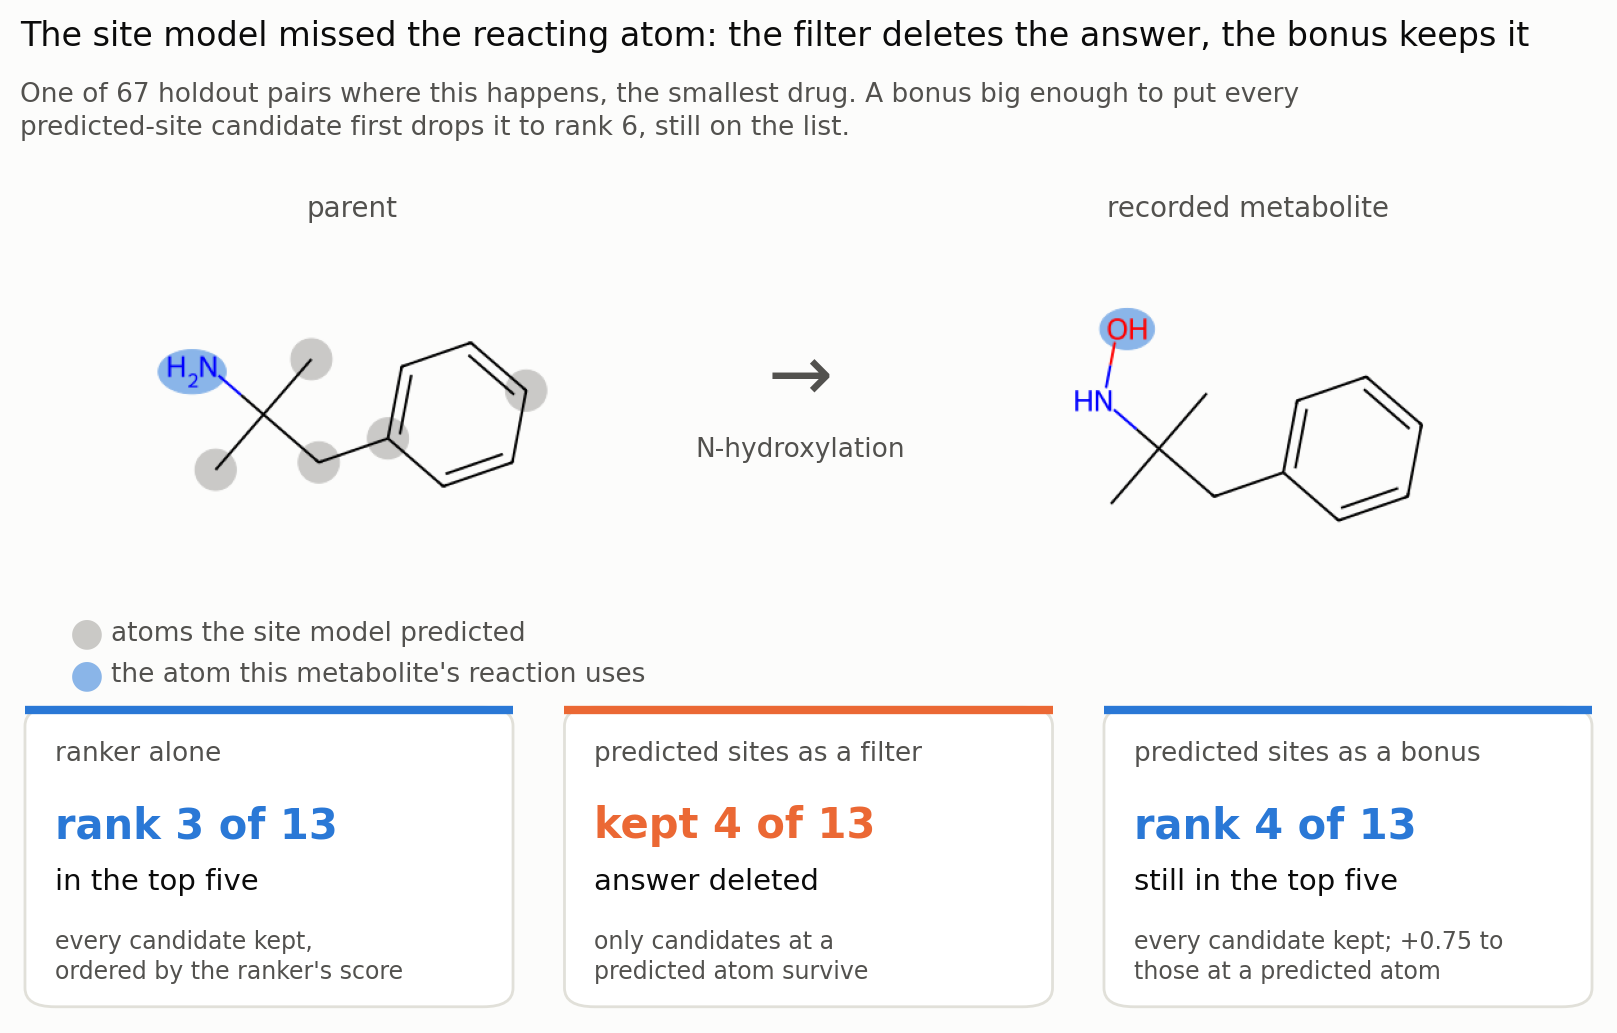

  pairs the ranker finds, the filter deletes and the bonus keeps: 67
  CC(C)(N)Cc1ccccc1 -> CC(C)(Cc1ccccc1)NO: ranker 3, filter keeps 4/13, bonus 4, dominating bonus 6

In [ ]:
# One pair, three treatments: the mechanism behind the aggregate numbers. The example is chosen
# by rule: the smallest parent whose answer the ranker finds, the filter deletes,
# and the chosen bonus keeps in the top five.
import io
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from PIL import Image
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#898781"
INK, MUTED, LINE, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"

def full_rank(parent, lam, keep=None):
    """Every candidate in ranked order, as standardised keys, under bonus lam."""
    cands = [c for c in scores_test[parent] if keep is None or c in keep]
    if not cands: return []
    bonus = [lam if candidates[parent].get(c, set()) & PRED.get(parent, set()) else 0.0 for c in cands]
    ranked = dec.rank_candidates(cands, [scores_test[parent][c] + b for c, b in zip(cands, bonus)],
                                 parent, k=len(cands)).predictions
    return [ev.match_key(c, "standardized") for c in ranked]

cases = []
for parent, target in test_pairs:
    key = ev.match_key(target, "standardized")
    gated = {c for c, s in candidates[parent].items() if s & PRED.get(parent, set())}
    base, gate, prior = full_rank(parent, 0.0), full_rank(parent, 0.0, gated), full_rank(parent, BEST)
    if key in base[:K] and key not in gate and key in prior[:K]:
        cases.append((Chem.MolFromSmiles(parent).GetNumHeavyAtoms(), parent, target, key,
                      base, gate, prior, full_rank(parent, 1e6)))
print(f"  pairs the ranker finds, the filter deletes and the bonus keeps: {len(cases)}")
_, parent, target, key, base, gate, prior, saturated = min(cases, key=lambda c: c[0])
answer = next(c for c in candidates[parent] if ev.match_key(c, "standardized") == key)

def draw(mol, colours, size=(420, 300)):
    d = rdMolDraw2D.MolDraw2DCairo(*size)
    o = d.drawOptions()
    o.setBackgroundColour((0.988, 0.988, 0.984, 1)); o.fixedBondLength = 38
    o.bondLineWidth = 2; o.minFontSize = 20; o.highlightRadius = 0.42
    d.DrawMolecule(mol, highlightAtoms=list(colours), highlightAtomColors=colours,
                   highlightBonds=[])
    d.FinishDrawing()
    return Image.open(io.BytesIO(d.GetDrawingText()))

rgb = lambda h, a=0.55: tuple(int(h[i:i + 2], 16) / 255 * a + (1 - a) for i in (1, 3, 5))
pmol, mmol = Chem.MolFromSmiles(parent), Chem.MolFromSmiles(answer)
rdDepictor.Compute2DCoords(pmol)
match = mmol.GetSubstructMatch(pmol)
if match:
    rdDepictor.GenerateDepictionMatching2DStructure(mmol, pmol)
predicted, reacting = PRED.get(parent, set()), candidates[parent][answer]
p_colours = {i: rgb(GREY, 0.45) for i in predicted - reacting}
p_colours.update({i: rgb(BLUE) for i in reacting})
m_colours = {i: rgb(BLUE) for i in range(mmol.GetNumAtoms()) if i not in set(match)}

fig = plt.figure(figsize=(8.3, 5.2))
fig.patch.set_facecolor(SURFACE)
for img, x0, title in ((draw(pmol, p_colours), 0.02, "parent"),
                       (draw(mmol, m_colours), 0.56, "recorded metabolite")):
    a = fig.add_axes([x0, 0.42, 0.42, 0.37]); a.imshow(img); a.axis("off")
    a.set_title(title, color=MUTED, fontsize=10, pad=2)
fig.text(0.5, 0.64, "→", ha="center", va="center", fontsize=28, color=MUTED)
fig.text(0.5, 0.565, min(made_by[parent][key], key=RULE_ORDER.get), ha="center", color=MUTED,
         fontsize=9.5)
fig.text(0.06, 0.395, "●", color=rgb(GREY, 0.45), fontsize=14, va="center")
fig.text(0.085, 0.395, "atoms the site model predicted", color=MUTED, fontsize=9.5, va="center")
fig.text(0.06, 0.355, "●", color=rgb(BLUE), fontsize=14, va="center")
fig.text(0.085, 0.355, "the atom this metabolite's reaction uses", color=MUTED, fontsize=9.5,
         va="center")

n = len(base)
CARDS = [("ranker alone", f"rank {base.index(key) + 1} of {n}", "in the top five", BLUE,
          "every candidate kept,\nordered by the ranker's score"),
         ("predicted sites as a filter", f"kept {len(gate)} of {n}", "answer deleted", ORANGE,
          "only candidates at a\npredicted atom survive"),
         ("predicted sites as a bonus", f"rank {prior.index(key) + 1} of {n}",
          "still in the top five", BLUE, f"every candidate kept; +{BEST:g} to\nthose at a predicted atom")]
for j, (head, big, verdict, colour, how) in enumerate(CARDS):
    x0 = 0.03 + j * 0.325
    a = fig.add_axes([x0, 0.03, 0.30, 0.30]); a.axis("off"); a.set_xlim(0, 1); a.set_ylim(0, 1)
    a.add_patch(FancyBboxPatch((0.01, 0.02), 0.98, 0.96, boxstyle="round,pad=0,rounding_size=0.06",
                               facecolor="white", edgecolor=LINE, linewidth=1))
    a.plot([0.01, 0.99], [0.97, 0.97], color=colour, linewidth=3, solid_capstyle="butt")
    a.text(0.07, 0.83, head, color=MUTED, fontsize=9.5, va="center")
    a.text(0.07, 0.60, big, color=colour, fontsize=15, fontweight="bold", va="center")
    a.text(0.07, 0.42, verdict, color=INK, fontsize=10.5, va="center")
    a.text(0.07, 0.18, how, color=MUTED, fontsize=8.5, va="center", linespacing=1.3)
fig.suptitle("The site model missed the reacting atom: the filter deletes the answer, "
             "the bonus keeps it", color=INK, fontsize=12, x=0.03, ha="left", y=0.985)
fig.text(0.03, 0.925, f"One of {len(cases)} holdout pairs where this happens, the smallest drug. A "
         f"bonus big enough to put every\npredicted-site candidate first drops it to rank "
         f"{saturated.index(key) + 1}, still on the list.",
         color=MUTED, fontsize=9.5, ha="left", va="top", linespacing=1.35)
plt.savefig(ROOT / "docs" / "som_example.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print(f"  {parent} -> {answer}: ranker {base.index(key) + 1}, filter keeps {len(gate)}/{n}, "
      f"bonus {prior.index(key) + 1}, dominating bonus {saturated.index(key) + 1}")